In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')
from sklearn.linear_model import Lasso,LassoCV,Ridge,RidgeCV,ElasticNet,ElasticNetCV
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score
from sklearn.preprocessing import StandardScaler

In [3]:
df= pd.read_csv('banking_dataset.csv')

In [4]:
df.shape

(1000, 31)

In [5]:
df.head()

,customer_age,account_balance,annual_income,loan_amount,loan_duration_months,num_of_credit_cards,credit_card_utilization,monthly_salary,num_of_loans,num_of_defaults,num_of_transactions,avg_transaction_value,loan_to_income_ratio,credit_score,investment_value,savings_account_balance,fixed_deposit_amount,num_of_dependents,customer_tenure_years,emi_amount,house_value,insurance_amount,spending_score,digital_transactions_ratio,mobile_banking_usage_hours,branch_visits_per_month,internet_banking_logins,loan_interest_rate,customer_satisfaction_score,risk_factor,bank_profit
0,56,17871.07,1131740.96,409401.23,51,3,0.84,54136.15,2,2,116,794.15,0.93,744.98,180479.30,21687.41,118224.95,3,9.00,13161.09,3944259.84,128309.65,98.05,0.29,3.63,8,6,6.44,6.68,0.75,494405.22
1,69,54069.27,600090.95,188667.47,31,1,0.51,63632.00,3,2,308,1592.95,0.31,684.38,209806.33,12624.32,106389.64,2,11.93,7161.95,5528712.70,62273.87,0.33,0.89,6.29,6,21,10.82,2.43,0.11,268619.57
2,46,34872.99,756171.18,206035.43,13,3,0.53,63740.55,0,0,254,2639.78,0.40,730.88,90066.90,7322.53,206699.14,0,11.10,9485.74,6430959.82,91142.90,12.02,0.75,5.35,9,5,11.98,3.57,0.79,356441.45
3,32,21554.93,933147.71,318767.03,11,2,0.56,59817.85,1,2,227,1664.17,0.70,690.40,104209.23,34753.76,41556.60,1,3.95,12423.53,5152230.71,115780.27,54.69,0.93,10.51,0,5,6.37,2.89,0.03,373216.34
4,60,37068.54,345408.57,219029.55,29,0,0.17,49422.27,2,1,329,1215.09,0.29,723.49,126038.24,19304.24,157473.12,0,6.82,10080.06,3705329.29,85623.14,95.59,0.69,9.11,3,13,8.60,5.86,0.44,328103.09


In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 31 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   customer_age                 1000 non-null   int64  
 1   account_balance              1000 non-null   float64
 2   annual_income                1000 non-null   float64
 3   loan_amount                  1000 non-null   float64
 4   loan_duration_months         1000 non-null   int64  
 5   num_of_credit_cards          1000 non-null   int64  
 6   credit_card_utilization      1000 non-null   float64
 7   monthly_salary               1000 non-null   float64
 8   num_of_loans                 1000 non-null   int64  
 9   num_of_defaults              1000 non-null   int64  
 10  num_of_transactions          1000 non-null   int64  
 11  avg_transaction_value        1000 non-null   float64
 12  loan_to_income_ratio         1000 non-null   float64
 13  credit_score       

In [7]:
#### duplicates
df.duplicated().sum()

np.int64(0)

In [8]:
#### missing values
df.isnull().sum()

customer_age                   0
account_balance                0
annual_income                  0
loan_amount                    0
loan_duration_months           0
num_of_credit_cards            0
credit_card_utilization        0
monthly_salary                 0
num_of_loans                   0
num_of_defaults                0
num_of_transactions            0
avg_transaction_value          0
loan_to_income_ratio           0
credit_score                   0
investment_value               0
savings_account_balance        0
fixed_deposit_amount           0
num_of_dependents              0
customer_tenure_years          0
emi_amount                     0
house_value                    0
insurance_amount               0
spending_score                 0
digital_transactions_ratio     0
mobile_banking_usage_hours     0
branch_visits_per_month        0
internet_banking_logins        0
loan_interest_rate             0
customer_satisfaction_score    0
risk_factor                    0
bank_profi

In [9]:
target= df[['bank_profit']]
features= df.drop(columns=['bank_profit'])

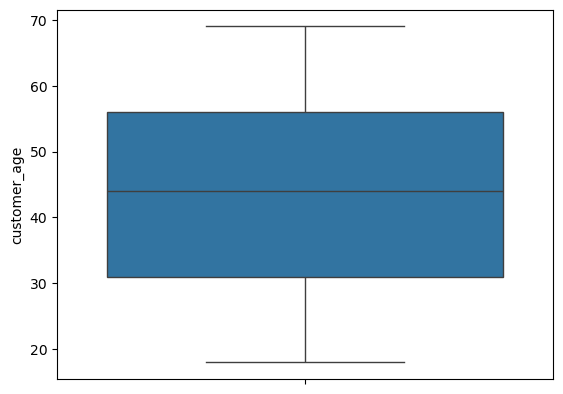

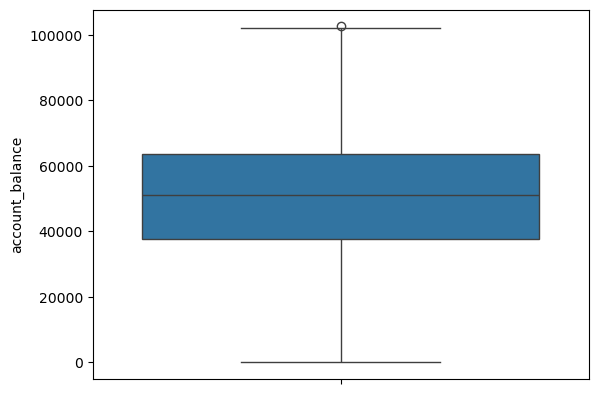

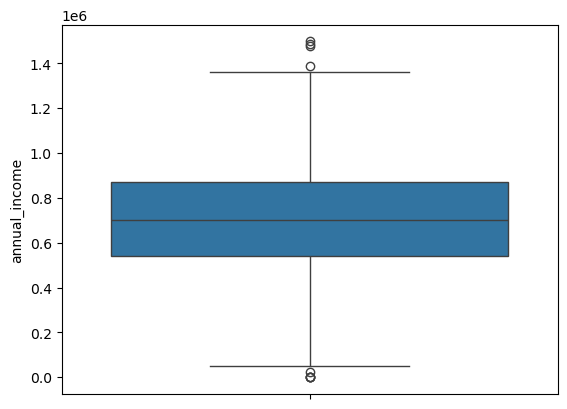

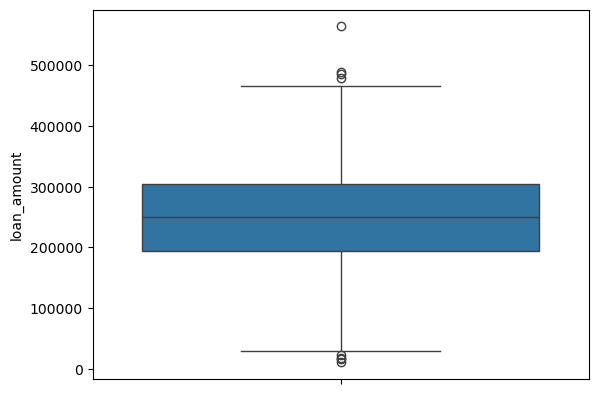

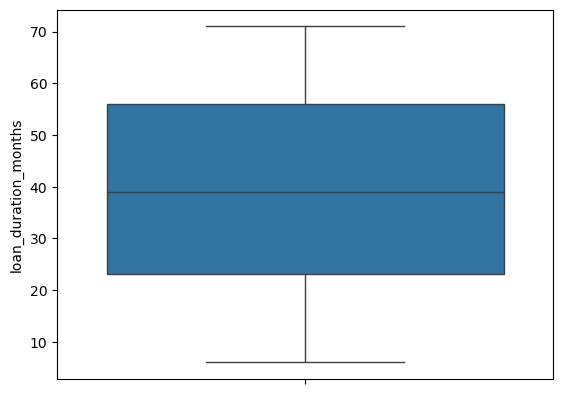

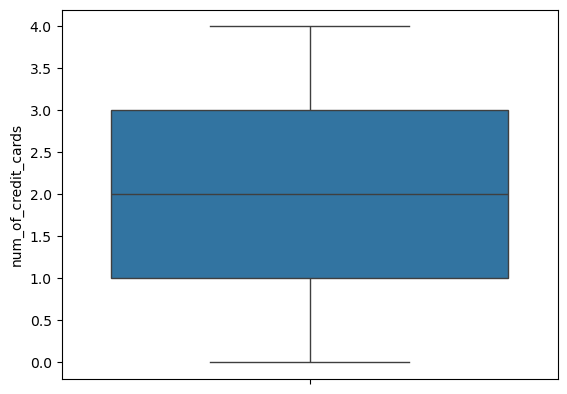

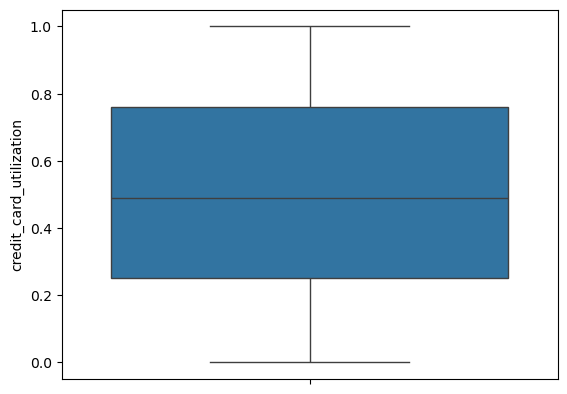

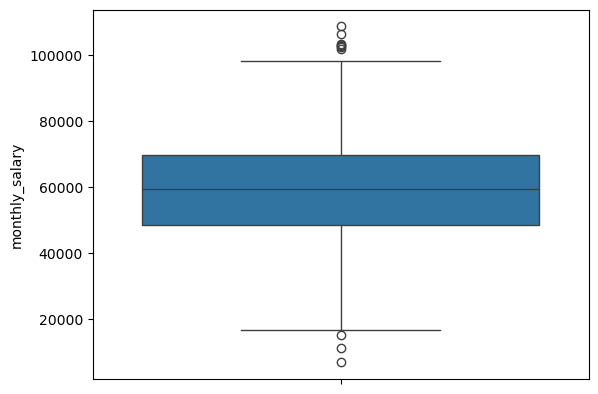

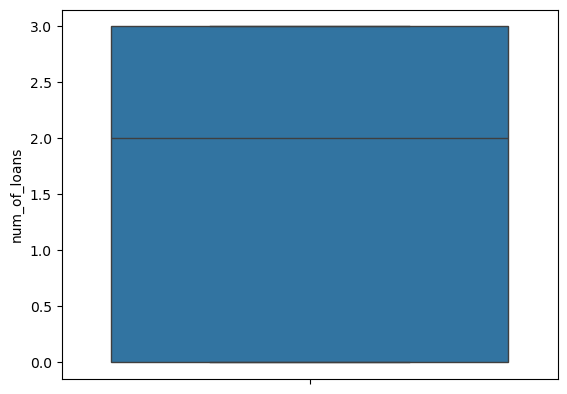

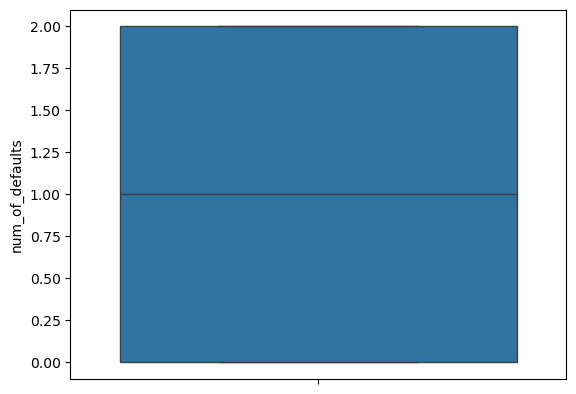

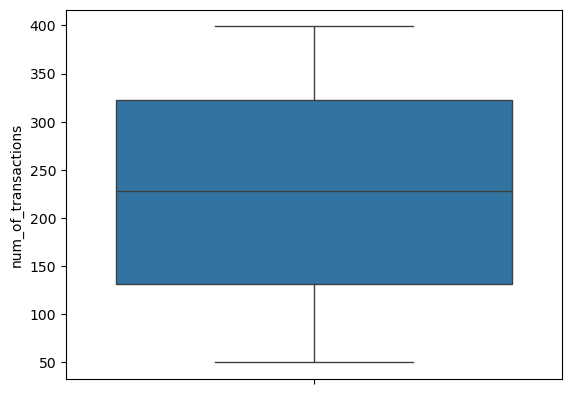

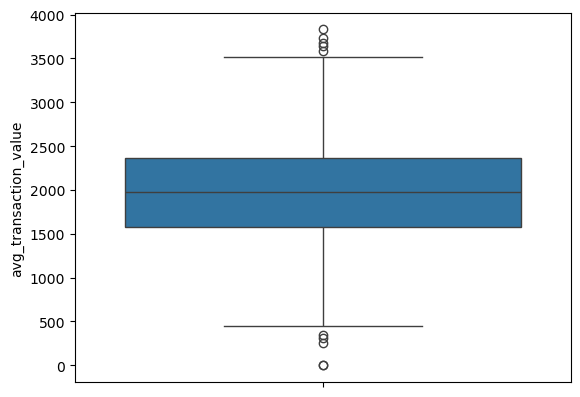

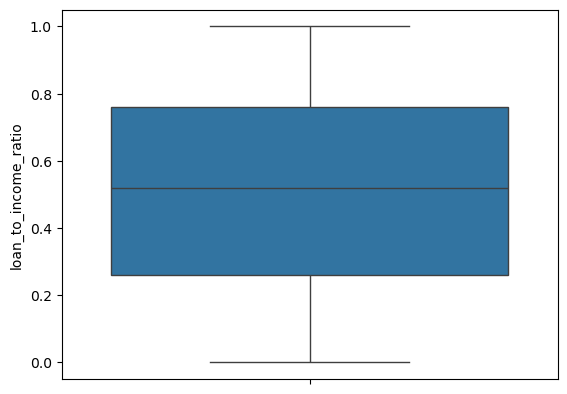

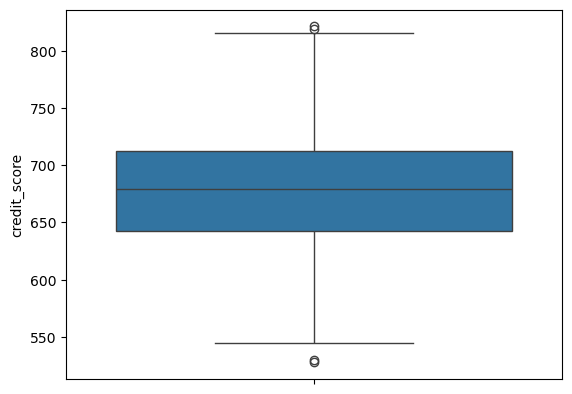

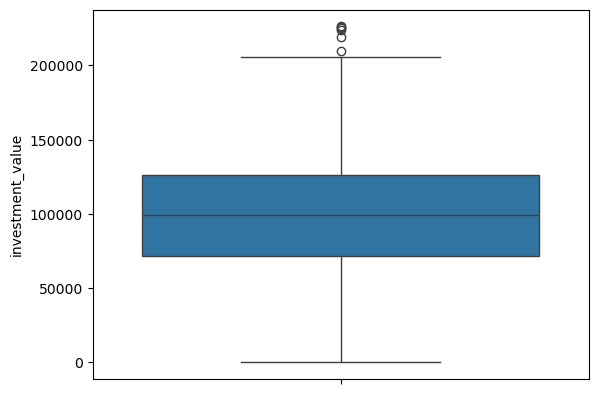

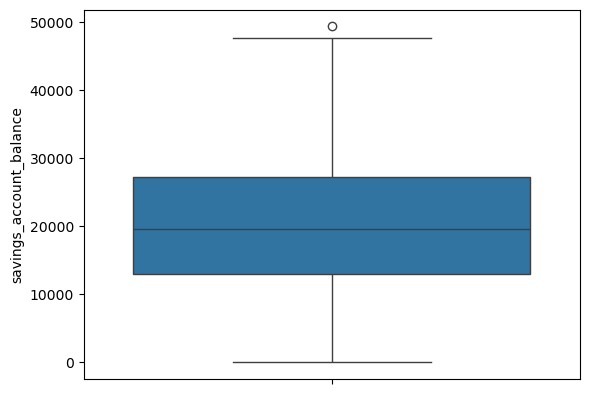

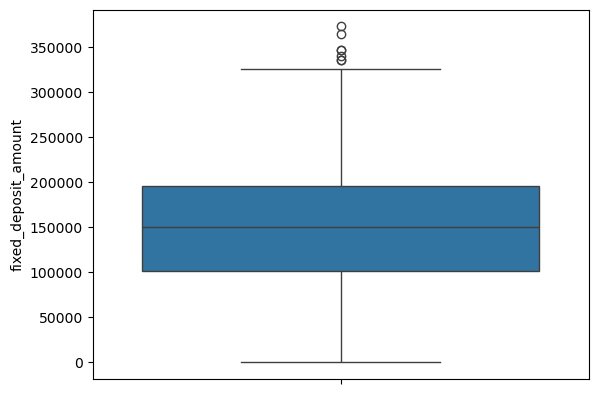

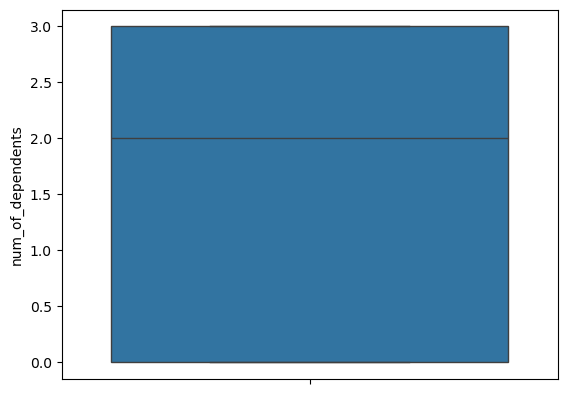

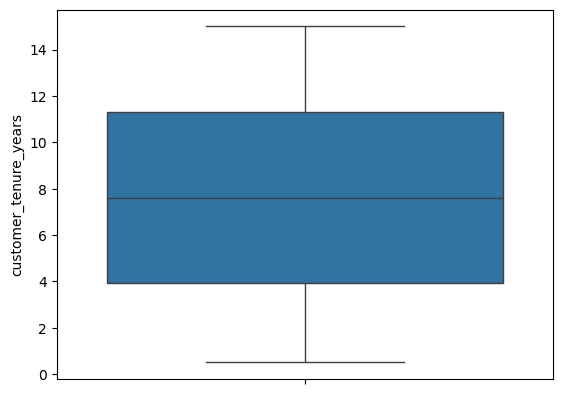

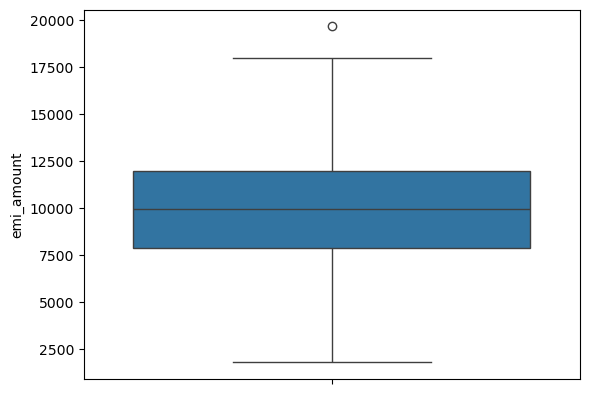

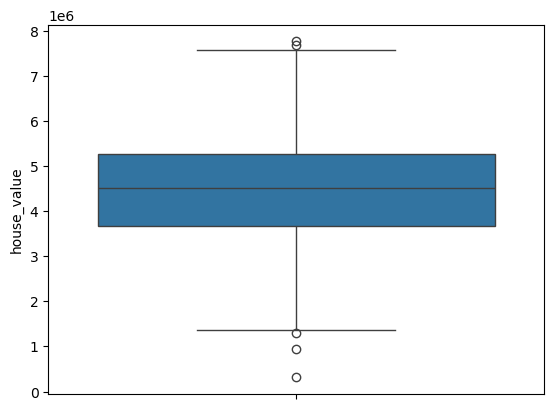

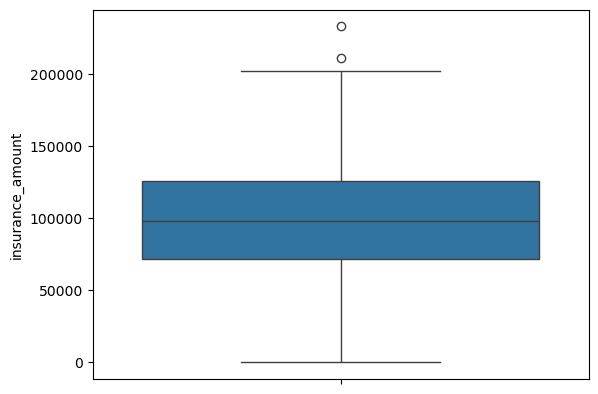

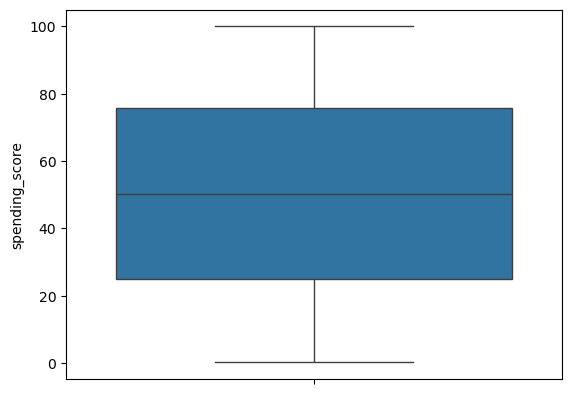

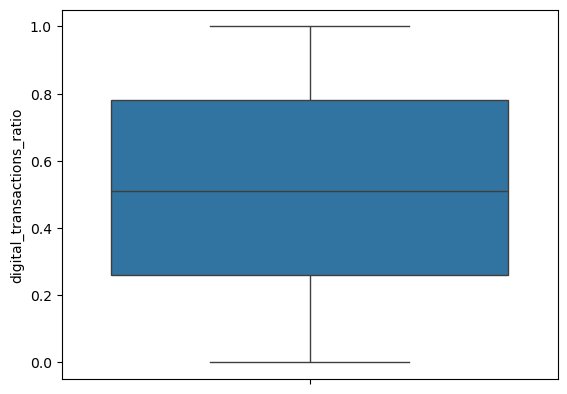

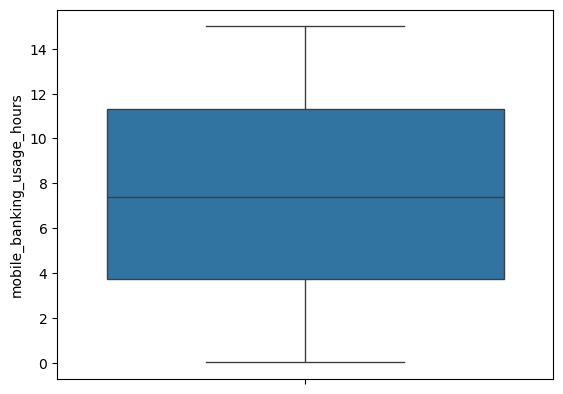

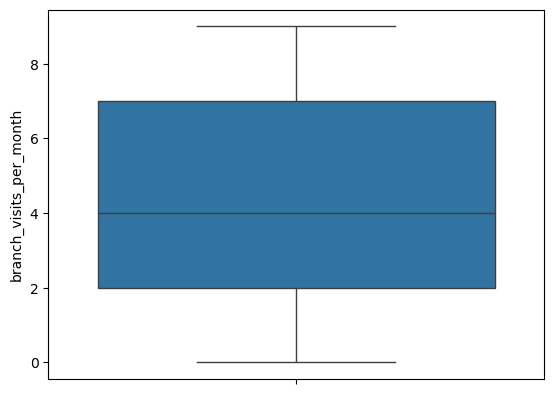

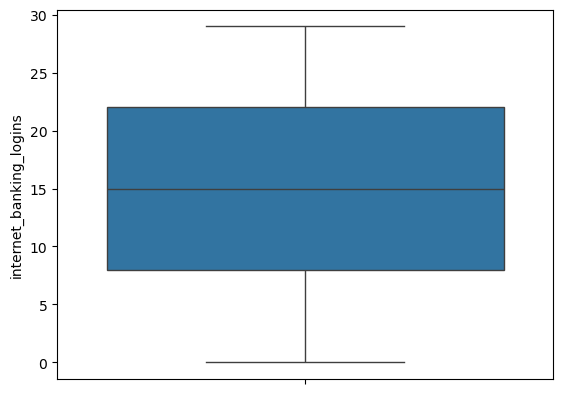

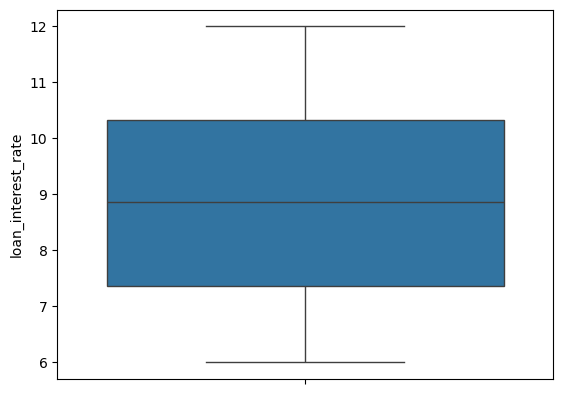

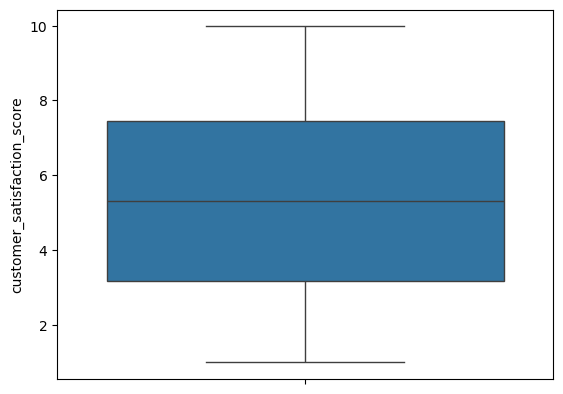

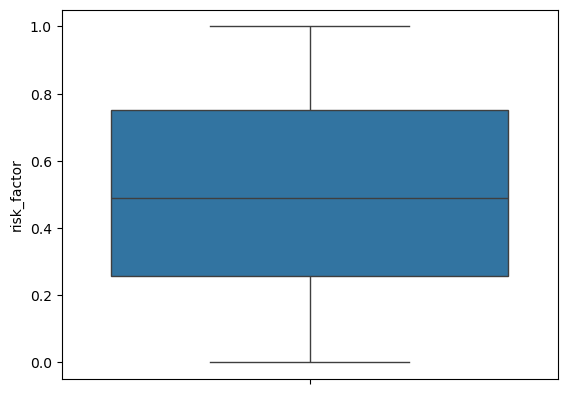

In [10]:
for col in features.columns:
    sns.boxplot(data=features,y=col)
    plt.show()

In [11]:
#### outlier capping
def outlier_capping(df,column):
    Q1= df[column].quantile(0.25)
    Q3= df[column].quantile(0.75)
    IQR= Q3-Q1
    lower_extreme= Q1-1.5*IQR
    uppper_extreme= Q3+1.5*IQR
    df[column]=df[column].apply(lambda x:lower_extreme if x<lower_extreme else uppper_extreme if x>uppper_extreme else x)
for col in features.select_dtypes(['int','float']).columns:
    outlier_capping(features,col)

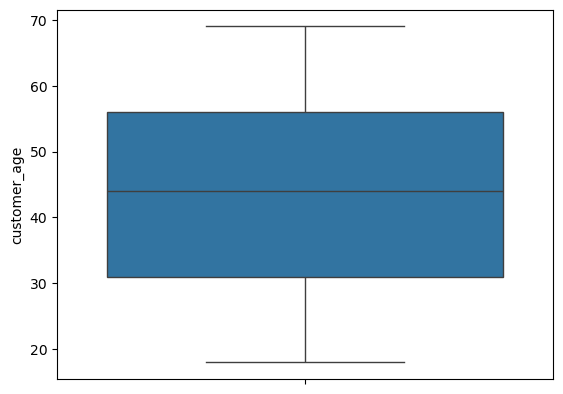

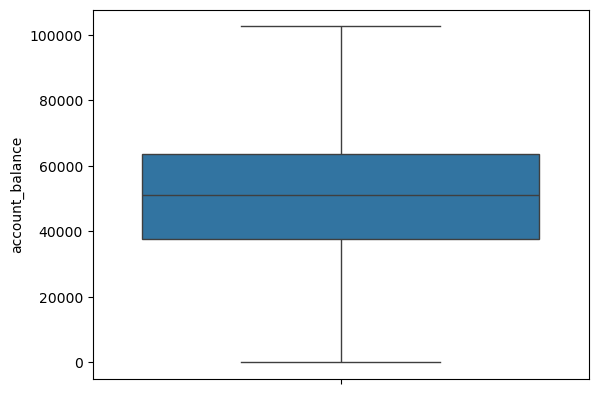

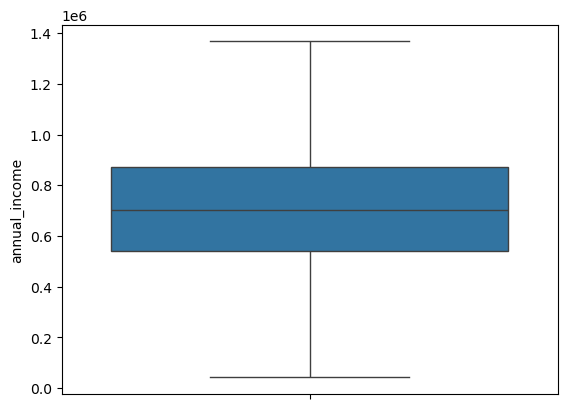

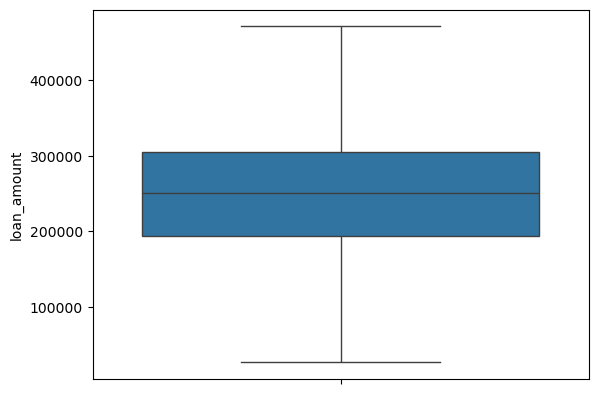

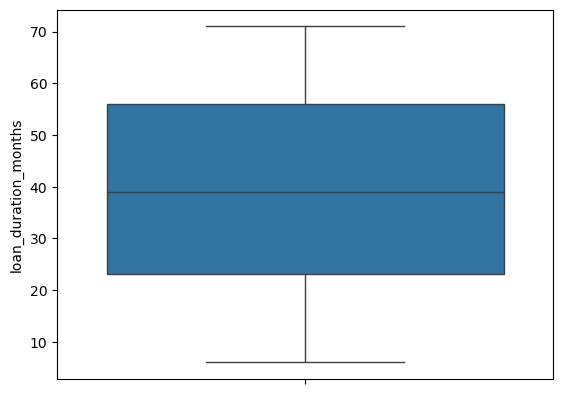

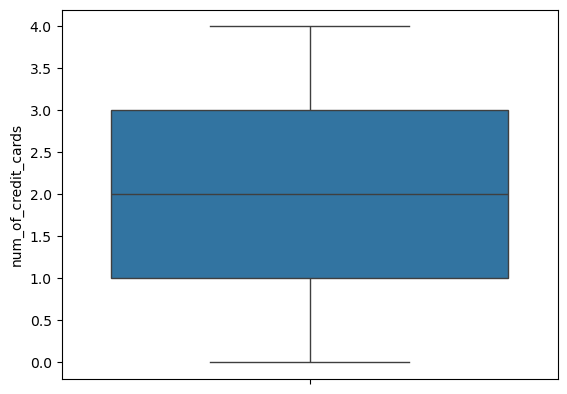

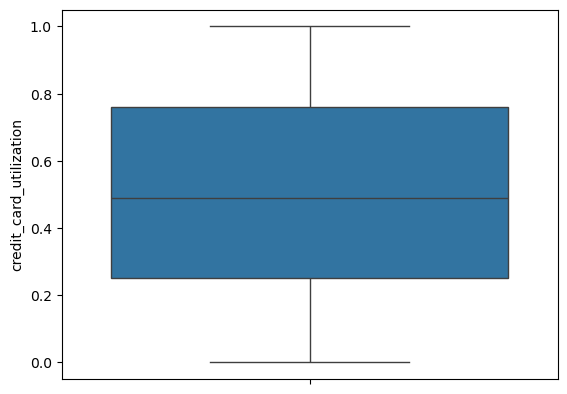

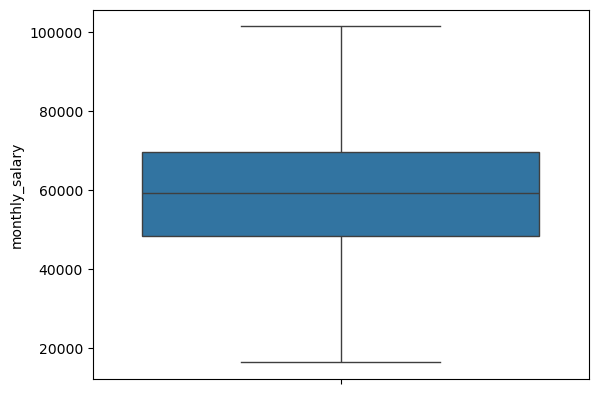

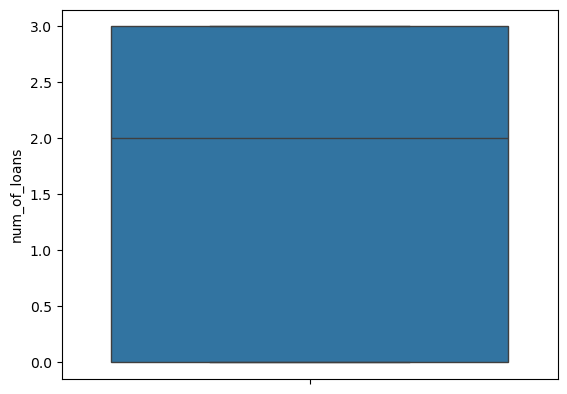

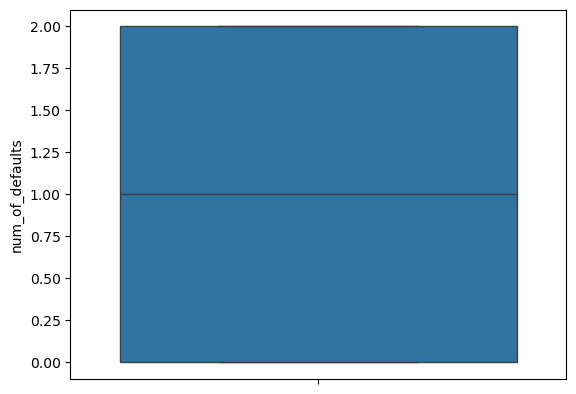

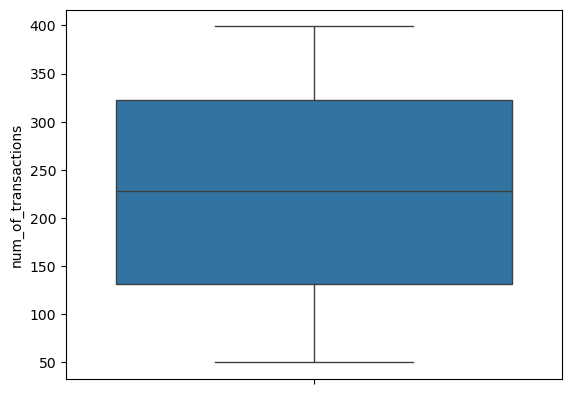

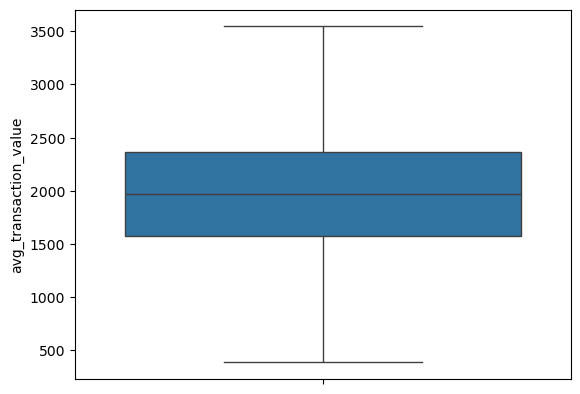

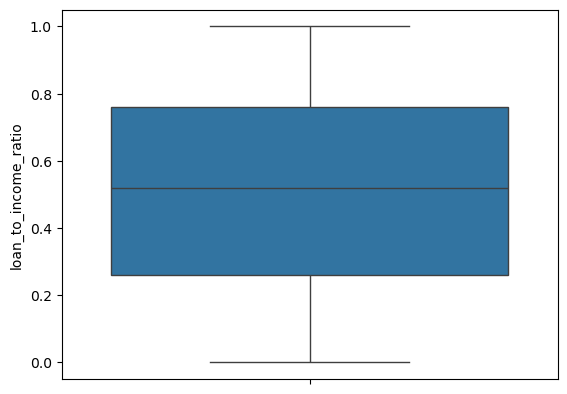

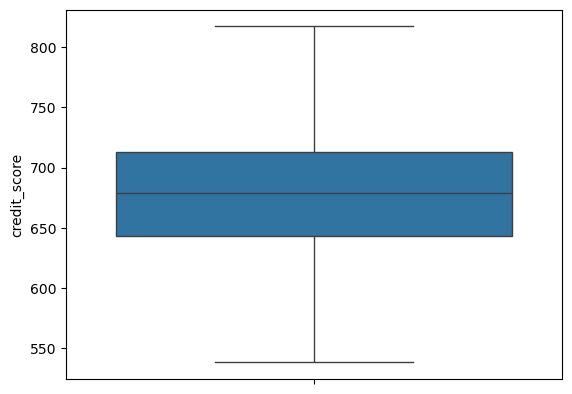

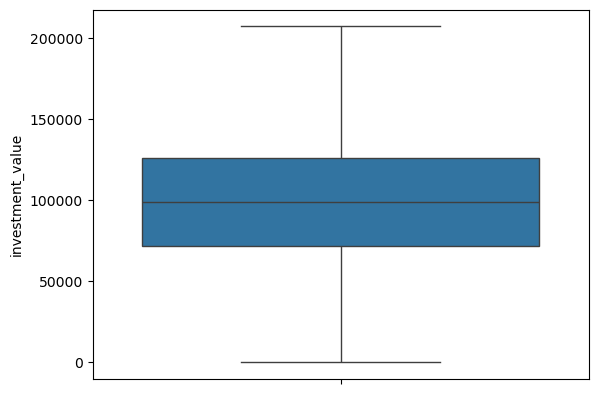

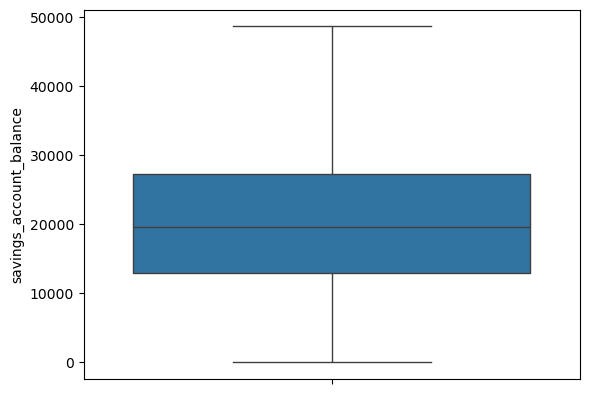

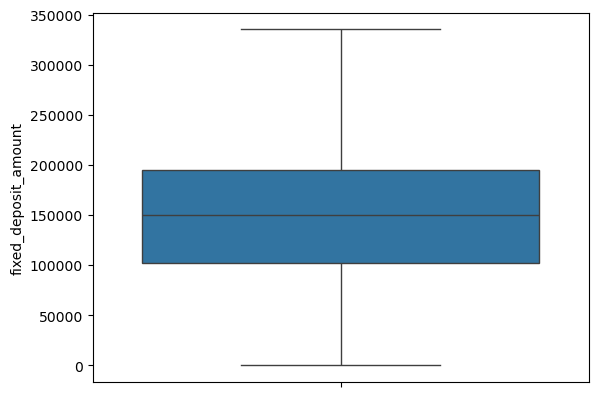

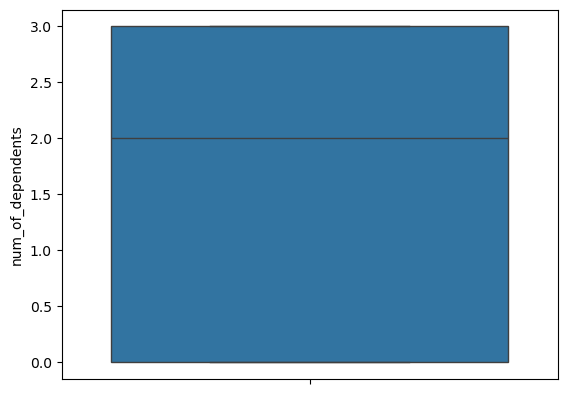

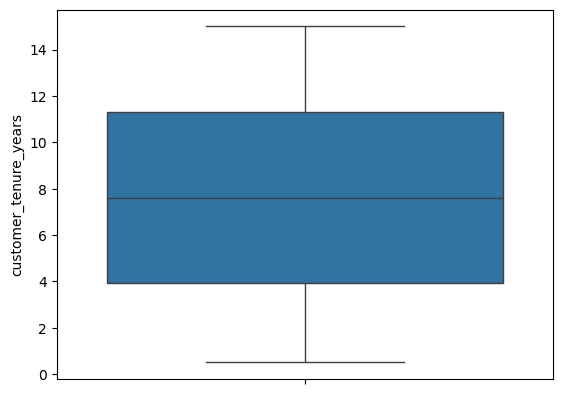

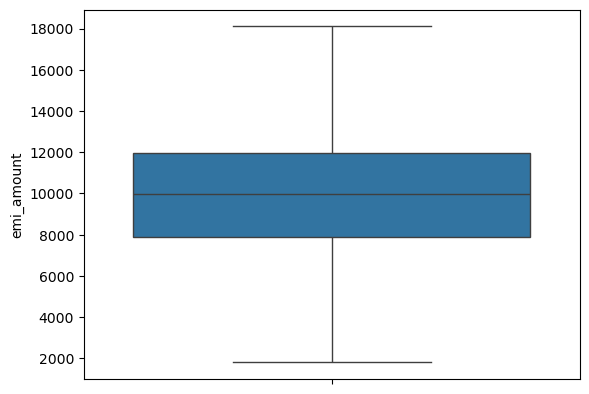

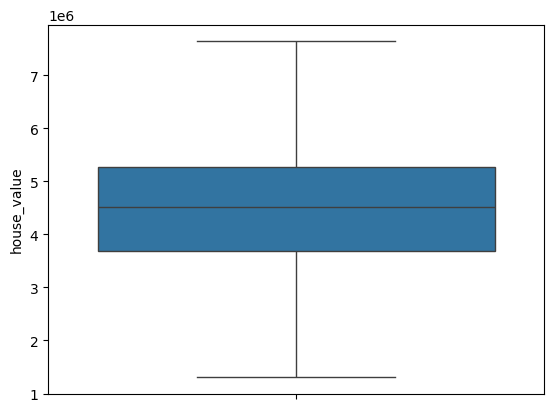

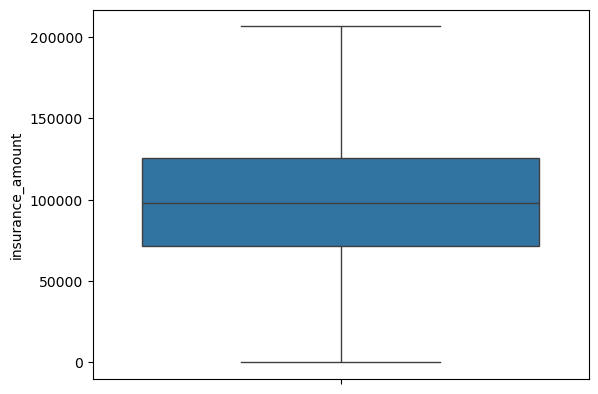

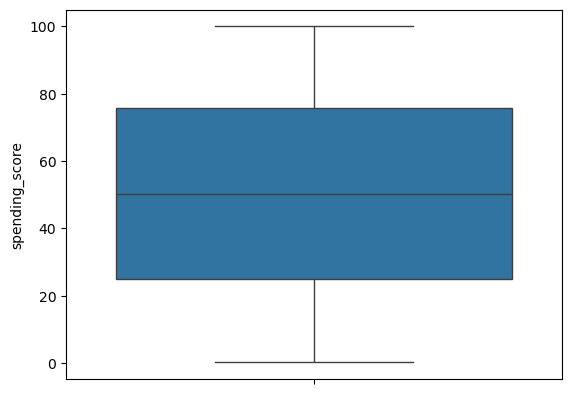

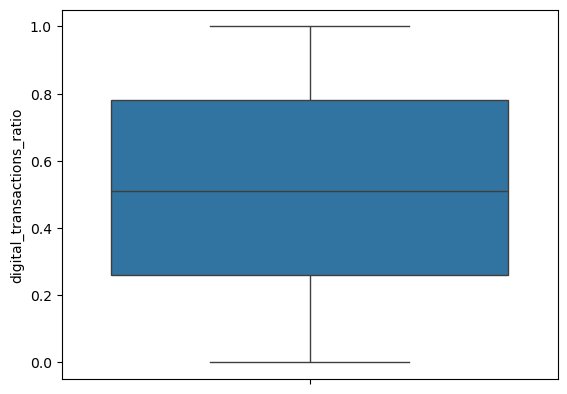

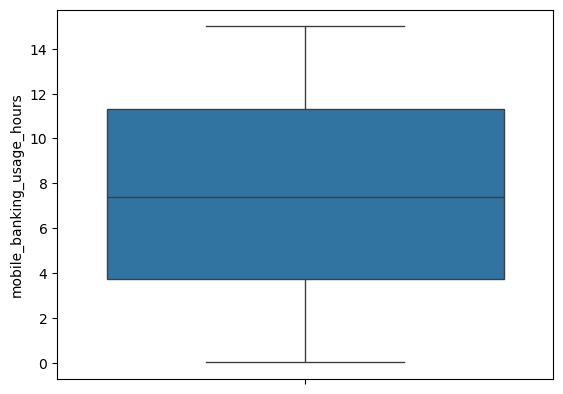

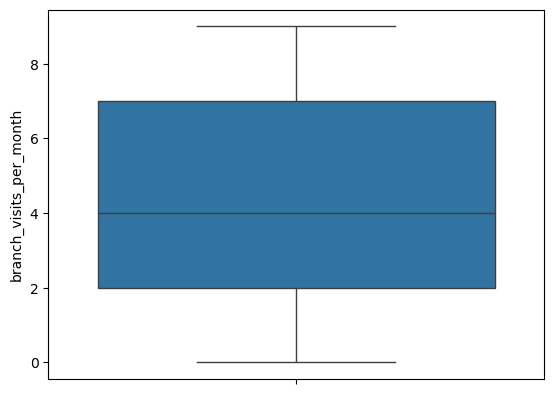

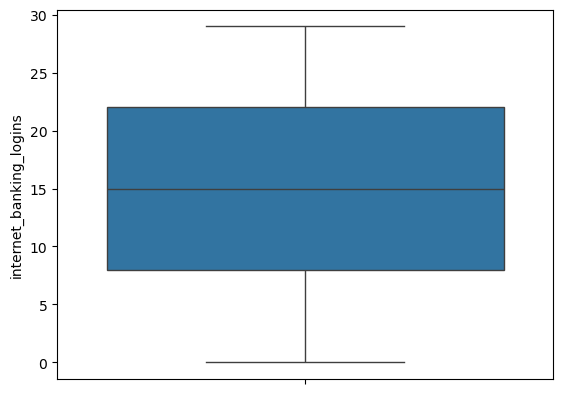

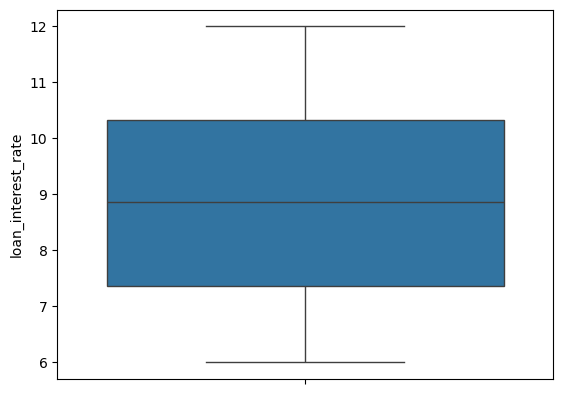

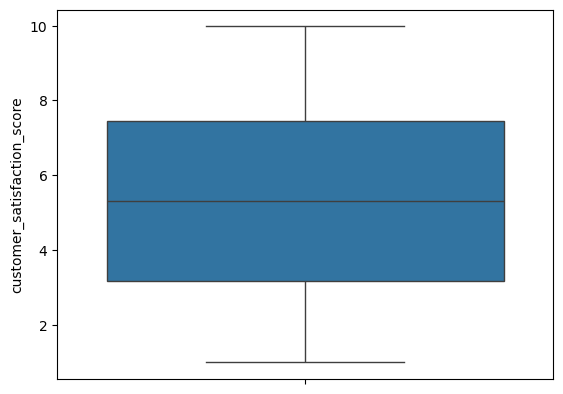

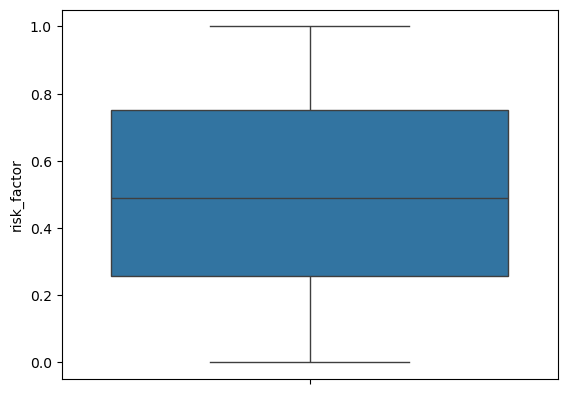

In [12]:
for col in features.columns:
    sns.boxplot(data=features,y=col)
    plt.show()

(0.0, 5.0)

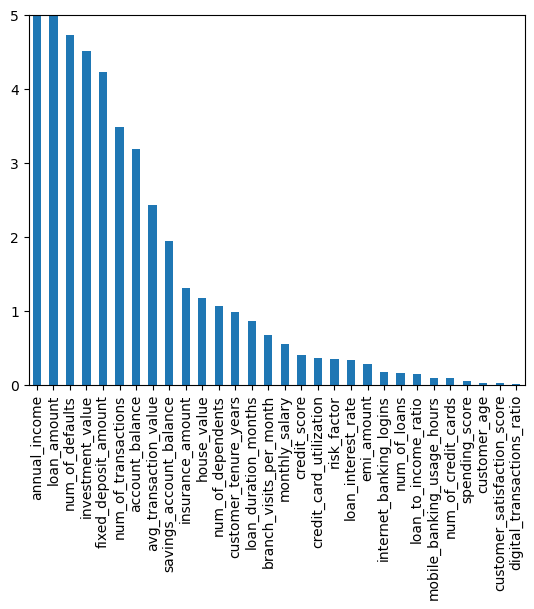

In [19]:
#### Feature Selection
from sklearn.feature_selection import f_regression
f_reg= f_regression(features,target)
pd.Series(f_reg[0],index=features.columns).sort_values(ascending=False).plot(kind='bar')
plt.ylim(0,5)

In [20]:
#### Train_Test_Split
x_train,x_test,y_train,y_test= train_test_split(features,target,train_size=0.8,random_state=100)
print(x_train.shape)
print(x_test.shape)
print(y_train.shape)
print(y_test.shape)

(800, 30)
(200, 30)
(800, 1)
(200, 1)


In [22]:
float_col= x_train.select_dtypes(include=['float']).columns
print(float_col)

Index(['account_balance', 'annual_income', 'loan_amount',
       'credit_card_utilization', 'monthly_salary', 'avg_transaction_value',
       'loan_to_income_ratio', 'credit_score', 'investment_value',
       'savings_account_balance', 'fixed_deposit_amount',
       'customer_tenure_years', 'emi_amount', 'house_value',
       'insurance_amount', 'spending_score', 'digital_transactions_ratio',
       'mobile_banking_usage_hours', 'loan_interest_rate',
       'customer_satisfaction_score', 'risk_factor'],
      dtype='object')


In [23]:
len(float_col)

21

In [24]:
std_sca= StandardScaler()

In [25]:
x_train[float_col]= std_sca.fit_transform(x_train[float_col])
x_test[float_col]= std_sca.transform(x_test[float_col])
x_train.head()

,customer_age,account_balance,annual_income,loan_amount,loan_duration_months,num_of_credit_cards,credit_card_utilization,monthly_salary,num_of_loans,num_of_defaults,num_of_transactions,avg_transaction_value,loan_to_income_ratio,credit_score,investment_value,savings_account_balance,fixed_deposit_amount,num_of_dependents,customer_tenure_years,emi_amount,house_value,insurance_amount,spending_score,digital_transactions_ratio,mobile_banking_usage_hours,branch_visits_per_month,internet_banking_logins,loan_interest_rate,customer_satisfaction_score,risk_factor
675,26,2.208246,-0.337232,0.120770,56,1,0.345416,0.963002,1,0,233,-0.930359,-0.402275,-0.167430,-0.023879,-0.718283,-0.429428,1,1.303006,-1.004882,-0.609217,0.312289,1.486540,0.072067,0.479082,3,12,-1.155794,-0.286445,0.990270
358,44,-0.113755,-0.144286,0.305375,60,1,1.388442,-0.016881,2,2,224,0.439726,1.126726,0.508701,-0.481590,0.054209,-0.855015,1,-1.247052,-0.907810,0.848560,0.876603,-0.012377,-0.815436,0.415180,0,17,0.731534,-0.053266,1.301894
159,66,1.619736,1.427169,-0.203852,61,4,0.136810,0.310059,3,0,306,-1.219991,1.230976,1.467727,0.536986,2.392900,0.548718,1,-0.918850,1.219781,0.670759,-1.809452,-0.068033,-1.020245,1.544883,7,1,0.719991,0.737174,-0.533222
533,40,0.135779,-0.210875,1.041706,57,3,1.492745,-0.311001,3,2,132,0.112835,0.779225,-1.022358,-0.779162,-1.245095,-1.009880,1,-1.558726,0.541548,1.532477,-1.934282,0.677475,-1.395727,1.631607,1,8,0.558385,1.116585,1.544268
678,34,-2.585092,-1.146789,-0.588950,62,3,1.492745,0.348638,2,2,393,0.909093,-1.062525,-0.586840,-0.094243,-0.805814,0.419368,3,-0.413561,-0.262227,1.151230,0.720881,0.514631,0.959570,-1.412884,0,8,-0.999959,0.583038,-0.256224


In [26]:
#### Lasso
lasso= Lasso(alpha=1,max_iter=1000)
lasso.fit(x_train,y_train)

Lasso(alpha=1)

In [27]:
lasso.coef_

array([-4.04159360e+01, -3.63708085e+03,  7.43452743e+04,  2.08519200e+04,
       -8.79746016e+01, -9.90900517e+02,  9.25838085e+02,  3.06958517e+02,
        2.15923826e+03, -6.71196147e+03, -2.65596215e+01, -2.35696191e+03,
       -1.48246786e+03,  1.02165543e+03,  6.31832323e+03,  2.11466102e+02,
       -2.43927686e+03, -4.56208340e+02, -7.32727514e+02,  2.12385793e+01,
       -1.18021260e+03, -4.74090571e+02,  2.44369054e+02, -1.01144538e+03,
        4.77278375e+02,  9.02646724e+02,  2.21954915e+02,  6.37809767e+02,
       -2.54695028e+03, -8.00261820e+02])

In [28]:
lasso.intercept_

array([293812.98277528])

In [31]:
y_pred= lasso.predict(x_train)
y_pred1= lasso.predict(x_test)
train_acc= r2_score(y_train,y_pred)
test_acc= r2_score(y_test,y_pred1)
print('Train_Acc:',train_acc,',','Test_Acc:',test_acc)

Train_Acc: 0.7268949183845497 , Test_Acc: 0.6991907029255952


In [32]:
lassocv= LassoCV(n_alphas=100,max_iter=1000,cv=10)
lassocv.fit(x_train,y_train)

LassoCV(cv=10)

In [36]:
alphas=lassocv.alphas_
best_alpha= lassocv.alpha_
best_alpha

np.float64(1479.3560933859717)

In [53]:
coeff=lassocv.coef_

In [46]:
#### mean_cross_validation_error
mcve=lassocv.mse_path_.mean(axis=1)

(0.0, 5000.0)

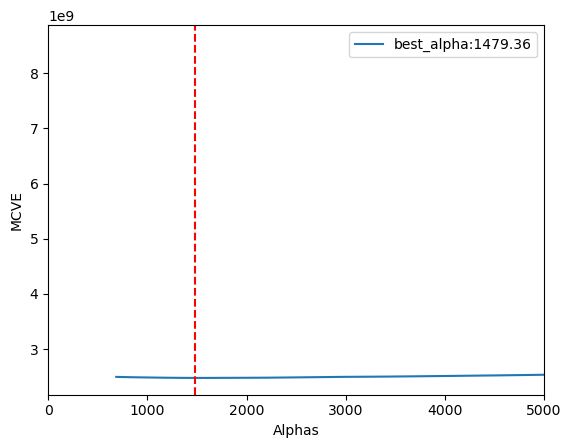

In [52]:
plt.plot(alphas,mcve,label=f'best_alpha:{best_alpha:.2f}')
plt.axvline(best_alpha,linestyle='--',color='red')
plt.legend()
plt.xlabel('Alphas')
plt.ylabel('MCVE')
plt.xlim(0,5000)

In [55]:
np.sum(coeff==0)

np.int64(14)

In [56]:
np.sum(coeff!=0)

np.int64(16)

In [57]:
np.nonzero(coeff)

(array([ 0,  1,  2,  3,  4,  5,  8,  9, 10, 11, 14, 16, 20, 25, 26, 28]),)

In [62]:
selected_features=features.columns[np.nonzero(coeff)]
selected_features

Index(['customer_age', 'account_balance', 'annual_income', 'loan_amount',
       'loan_duration_months', 'num_of_credit_cards', 'num_of_loans',
       'num_of_defaults', 'num_of_transactions', 'avg_transaction_value',
       'investment_value', 'fixed_deposit_amount', 'house_value',
       'branch_visits_per_month', 'internet_banking_logins',
       'customer_satisfaction_score'],
      dtype='object')

In [63]:
features[selected_features]

,customer_age,account_balance,annual_income,loan_amount,loan_duration_months,num_of_credit_cards,num_of_loans,num_of_defaults,num_of_transactions,avg_transaction_value,investment_value,fixed_deposit_amount,house_value,branch_visits_per_month,internet_banking_logins,customer_satisfaction_score
0,56,17871.07,1131740.96,409401.23,51,3,2,2,116,794.15,180479.300,118224.95,3944259.84,8,6,6.68
1,69,54069.27,600090.95,188667.47,31,1,3,2,308,1592.95,207370.955,106389.64,5528712.70,6,21,2.43
2,46,34872.99,756171.18,206035.43,13,3,0,0,254,2639.78,90066.900,206699.14,6430959.82,9,5,3.57
3,32,21554.93,933147.71,318767.03,11,2,1,2,227,1664.17,104209.230,41556.60,5152230.71,0,5,2.89
4,60,37068.54,345408.57,219029.55,29,0,2,1,329,1215.09,126038.240,157473.12,3705329.29,3,13,5.86
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
995,60,58390.65,1063315.17,81548.24,44,1,1,2,340,2112.58,109098.390,92807.41,2029389.30,1,1,2.88
996,64,32250.16,365348.55,342287.23,54,0,2,1,210,2271.75,109599.740,163737.07,4976007.03,4,7,1.82
997,62,41250.83,873229.66,360907.95,49,2,1,2,210,2300.90,78673.550,156100.15,4060862.10,5,19,4.70
998,35,64447.63,548534.79,225825.55,59,0,3,0,127,1265.18,93471.980,117520.89,6698482.64,0,10,4.16


In [64]:
y_pred= lassocv.predict(x_train)
y_pred1= lassocv.predict(x_test)
train_acc= r2_score(y_train,y_pred)
test_acc= r2_score(y_test,y_pred1)
print('Train_Acc:',train_acc,',','Test_Acc:',test_acc)

Train_Acc: 0.7232990162843436 , Test_Acc: 0.7010484537116006


#### Ridge

In [66]:
ridge=Ridge(alpha=1.0,max_iter=100)
ridge.fit(x_train,y_train)
y_pred= ridge.predict(x_train)
y_pred1= ridge.predict(x_test)
train_acc= r2_score(y_train,y_pred)
test_acc= r2_score(y_test,y_pred1)
print('Train_Acc:',train_acc,',','Test_Acc:',test_acc)

Train_Acc: 0.7268937839290481 , Test_Acc: 0.6990826583468528


In [67]:
ridgecv= RidgeCV(alphas=(1,2,5,7,8,10),cv=10)
ridgecv.fit(x_train,y_train)

RidgeCV(alphas=(1, 2, 5, 7, 8, 10), cv=10)

In [68]:
ridgecv.alpha_

np.int64(10)

In [69]:
y_pred= ridgecv.predict(x_train)
y_pred1= ridgecv.predict(x_test)
train_acc= r2_score(y_train,y_pred)
test_acc= r2_score(y_test,y_pred1)
print('Train_Acc:',train_acc,',','Test_Acc:',test_acc)

Train_Acc: 0.7267838272635935 , Test_Acc: 0.6980603318863556


In [70]:
ridgecv.coef_

array([-3.90854808e+01, -3.62733506e+03,  7.34063445e+04,  2.06119715e+04,
       -8.86828099e+01, -9.72542470e+02,  9.05655426e+02,  3.07336226e+02,
        2.11400349e+03, -6.59037414e+03, -2.71188641e+01, -2.24910257e+03,
       -1.42845427e+03,  9.86609916e+02,  6.25223907e+03,  1.85875798e+02,
       -2.47816112e+03, -4.67579208e+02, -7.25289365e+02, -2.01182508e+01,
       -1.23853666e+03, -4.33434464e+02,  2.15540594e+02, -9.67302499e+02,
        4.53567598e+02,  9.03262465e+02,  2.16838186e+02,  6.52662880e+02,
       -2.48232260e+03, -8.02091871e+02])

In [73]:
#### ElasticNet
elasticnet= ElasticNet(alpha=1.0,max_iter=1000,l1_ratio=0.8)
elasticnet.fit(x_train,y_train)
y_pred= elasticnet.predict(x_train)
y_pred1= elasticnet.predict(x_test)
train_acc= r2_score(y_train,y_pred)
test_acc= r2_score(y_test,y_pred1)
print('Train_Acc:',train_acc,',','Test_Acc:',test_acc)

Train_Acc: 0.7069210678802146 , Test_Acc: 0.6677112346813864


In [117]:
elasticnetcv= ElasticNetCV(n_alphas=1000,max_iter=100,cv=5,l1_ratio=[0.2,0.4,0.5,0.9,1])

In [113]:
elasticnetcv.fit(x_train,y_train)

ElasticNetCV(cv=5, l1_ratio=[0.2, 0.9, 1], max_iter=100, n_alphas=1000)

In [114]:
#### best_alpha
elasticnetcv.alpha_

np.float64(2209.260354094685)

In [115]:
#### best_l1_ratio
elasticnetcv.l1_ratio_

np.float64(1.0)

In [116]:
y_pred= elasticnetcv.predict(x_train)
y_pred1= elasticnetcv.predict(x_test)
train_acc= r2_score(y_train,y_pred)
test_acc= r2_score(y_test,y_pred1)
print('Train_Acc:',train_acc,',','Test_Acc:',test_acc)

Train_Acc: 0.7203632921228702 , Test_Acc: 0.7010290936047273
